## data visualizations

The following visualizations examine whether recent team performance and betting market information are related to actually NBA game outcomes. These relationships motivate the features used in the machine learning models

## modellinng

1. **Game Outcome Prediction:** Predict whether the home team will win using recent team performance from the previous 5 or 10 games.

2. **Betting Prediction:** Predict whether the home team will cover the closing point spread using recent team performance and the known pre-game closing spread.

For both tasks, Logistic Regression, K-Nearest Neighbors (KNN), and Random Forest models will be evaluated. Last 5 and Last 10 game features will also be compared.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("processed_data.csv")

df["GAME_DATE"] = pd.to_datetime(df["GAME_DATE"])

print("Dataset shape:", df.shape)
print("Date range:", df["GAME_DATE"].min(), "to", df["GAME_DATE"].max())
print("Missing values:", df.isna().sum().sum())

df.head()

Dataset shape: (2130, 40)
Date range: 2024-11-10 00:00:00 to 2026-04-12 00:00:00
Missing values: 1


,SEASON,GAME_ID,GAME_DATE,HOME_TEAM,AWAY_TEAM,HOME_WIN,HOME_PTS_LAST5,HOME_PTS_LAST10,HOME_REB_LAST5,HOME_REB_LAST10,...,AWAY_FG3_PCT_LAST5,AWAY_FG3_PCT_LAST10,AWAY_TOV_LAST5,AWAY_TOV_LAST10,AWAY_PLUS_MINUS_LAST5,AWAY_PLUS_MINUS_LAST10,AWAY_WIN_LAST5,AWAY_WIN_LAST10,close_spread_home,HOME_COVER
0,2024-25,22400210,2024-11-10,POR,MEM,0,107.2,107.2,41.6,44.2,...,0.3646,0.3562,17.2,16.8,15.8,5.8,0.8,0.6,1.5,0.0
1,2024-25,22400212,2024-11-11,CHI,CLE,0,116.2,114.8,42.0,46.8,...,0.4346,0.4160,13.2,13.5,7.2,10.8,1.0,1.0,8.5,1.0
2,2024-25,22400214,2024-11-11,NOP,BKN,0,109.2,107.2,37.4,40.5,...,0.3138,0.3449,14.4,15.0,-2.6,-1.1,0.4,0.4,1.5,0.0
3,2024-25,22400215,2024-11-11,OKC,LAC,1,114.2,115.7,42.4,44.4,...,0.4218,0.3766,17.4,17.2,3.8,2.2,0.8,0.6,-6.5,0.0
4,2024-25,22400216,2024-11-11,SAS,SAC,1,109.0,106.3,42.4,45.6,...,0.2636,0.3029,14.2,13.6,2.6,4.5,0.6,0.6,2.5,1.0


In [24]:
df = df.dropna(subset=["HOME_COVER"]).copy()
df = df.reset_index(drop=True)

df["HOME_COVER"] = df["HOME_COVER"].astype(int)

print("Dataset shape after removing push:", df.shape)
print("Missing values:", df.isna().sum().sum())

Dataset shape after removing push: (2129, 40)
Missing values: 0


In [25]:
# Difference between home and away teams' recent win rates
df["WIN_RATE_DIFF_LAST10"] = (
    df["HOME_WIN_LAST10"] - df["AWAY_WIN_LAST10"]
).round(1)

# Calculate actual home win rate for each difference
win_rate_analysis = (
    df.groupby("WIN_RATE_DIFF_LAST10")
      .agg(
          HOME_WIN_RATE=("HOME_WIN", "mean"),
          NUM_GAMES=("HOME_WIN", "count")
      )
      .reset_index()
)

win_rate_analysis

,WIN_RATE_DIFF_LAST10,HOME_WIN_RATE,NUM_GAMES
0,-1.0,0.000000,1
1,-0.9,0.000000,3
2,-0.8,0.000000,10
3,-0.7,0.250000,24
4,-0.6,0.192308,52
5,-0.5,0.243590,78
6,-0.4,0.339623,106
7,-0.3,0.408805,159
8,-0.2,0.445833,240
9,-0.1,0.454198,262


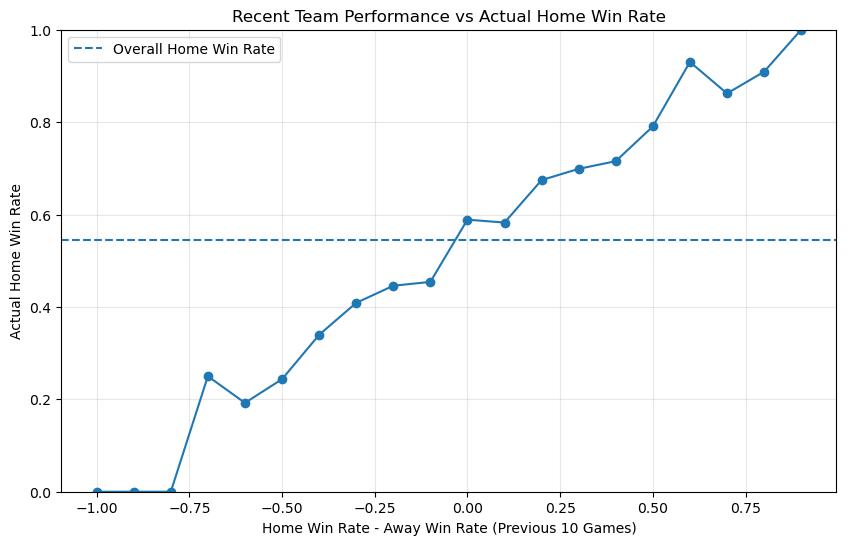

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(
    win_rate_analysis["WIN_RATE_DIFF_LAST10"],
    win_rate_analysis["HOME_WIN_RATE"],
    marker="o"
)

plt.axhline(
    y=df["HOME_WIN"].mean(),
    linestyle="--",
    label="Overall Home Win Rate"
)

plt.xlabel("Home Win Rate - Away Win Rate (Previous 10 Games)")
plt.ylabel("Actual Home Win Rate")
plt.title("Recent Team Performance vs Actual Home Win Rate")

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [27]:
# Difference between home and away teams' recent win rates
df["WIN_RATE_DIFF_LAST5"] = (
    df["HOME_WIN_LAST5"] - df["AWAY_WIN_LAST5"]
).round(1)

# Calculate actual home win rate for each difference
win_rate_analysis = (
    df.groupby("WIN_RATE_DIFF_LAST5")
      .agg(
          HOME_WIN_RATE=("HOME_WIN", "mean"),
          NUM_GAMES=("HOME_WIN", "count")
      )
      .reset_index()
)

win_rate_analysis

,WIN_RATE_DIFF_LAST5,HOME_WIN_RATE,NUM_GAMES
0,-1.0,0.153846,13
1,-0.8,0.159091,44
2,-0.6,0.331250,160
3,-0.4,0.369231,260
4,-0.2,0.504043,371
5,0.0,0.539863,439
6,0.2,0.623955,359
7,0.4,0.700000,250
8,0.6,0.746914,162
9,0.8,0.818182,55


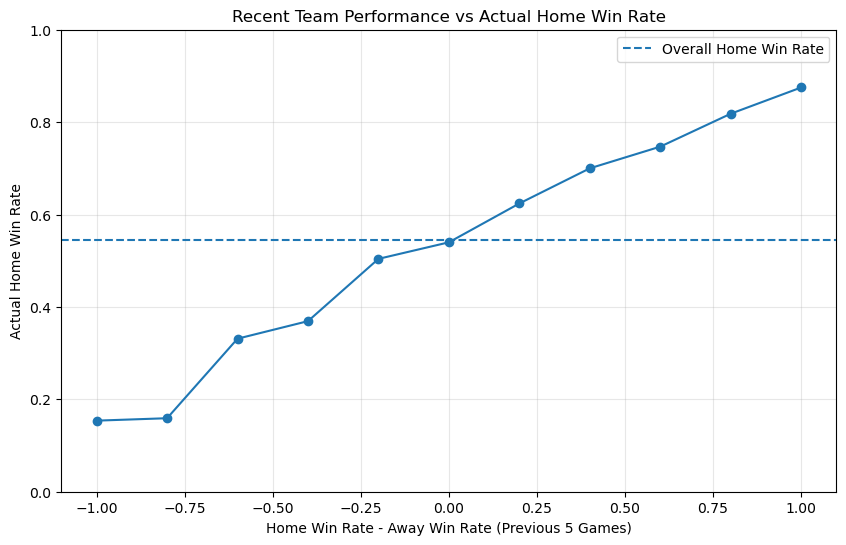

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(
    win_rate_analysis["WIN_RATE_DIFF_LAST5"],
    win_rate_analysis["HOME_WIN_RATE"],
    marker="o"
)

plt.axhline(
    y=df["HOME_WIN"].mean(),
    linestyle="--",
    label="Overall Home Win Rate"
)

plt.xlabel("Home Win Rate - Away Win Rate (Previous 5 Games)")
plt.ylabel("Actual Home Win Rate")
plt.title("Recent Team Performance vs Actual Home Win Rate")

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [29]:
cover_analysis = (
    df.groupby("WIN_RATE_DIFF_LAST5")
      .agg(
          HOME_COVER_RATE=("HOME_COVER", "mean"),
          NUM_GAMES=("HOME_COVER", "count")
      )
      .reset_index()
)

cover_analysis

,WIN_RATE_DIFF_LAST5,HOME_COVER_RATE,NUM_GAMES
0,-1.0,0.692308,13
1,-0.8,0.409091,44
2,-0.6,0.500000,160
3,-0.4,0.511538,260
4,-0.2,0.514825,371
5,0.0,0.503417,439
6,0.2,0.493036,359
7,0.4,0.508000,250
8,0.6,0.512346,162
9,0.8,0.563636,55


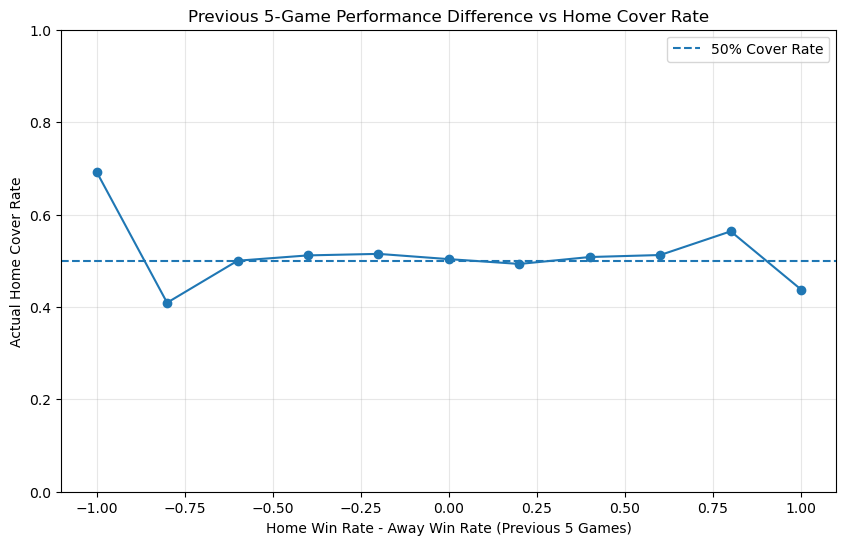

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(
    cover_analysis["WIN_RATE_DIFF_LAST5"],
    cover_analysis["HOME_COVER_RATE"],
    marker="o"
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="50% Cover Rate"
)

plt.xlabel("Home Win Rate - Away Win Rate (Previous 5 Games)")
plt.ylabel("Actual Home Cover Rate")
plt.title("Previous 5-Game Performance Difference vs Home Cover Rate")

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [31]:
spread_bins = [-20, -10, -5, 0, 5, 10, 20]

df["SPREAD_GROUP"] = pd.cut(
    df["close_spread_home"],
    bins=spread_bins
)

spread_analysis = (
    df.groupby("SPREAD_GROUP", observed=True)
      .agg(
          HOME_WIN_RATE=("HOME_WIN", "mean"),
          NUM_GAMES=("HOME_WIN", "count")
      )
      .reset_index()
)

spread_analysis

,SPREAD_GROUP,HOME_WIN_RATE,NUM_GAMES
0,"(-20, -10]",0.828729,362
1,"(-10, -5]",0.744035,461
2,"(-5, 0]",0.556098,410
3,"(0, 5]",0.427861,402
4,"(5, 10]",0.295082,305
5,"(10, 20]",0.101124,178


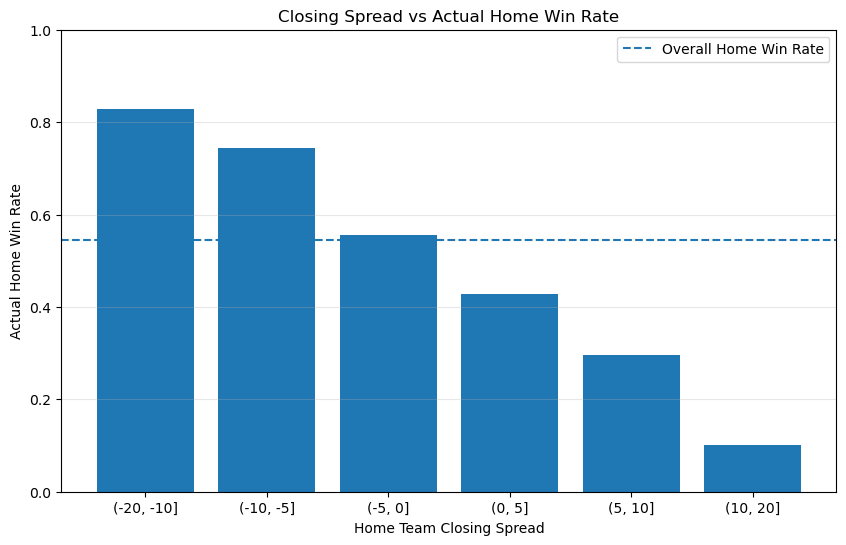

In [32]:
spread_analysis["SPREAD_LABEL"] = (
    spread_analysis["SPREAD_GROUP"].astype(str)
)

plt.figure(figsize=(10, 6))

plt.bar(
    spread_analysis["SPREAD_LABEL"],
    spread_analysis["HOME_WIN_RATE"]
)

plt.axhline(
    y=df["HOME_WIN"].mean(),
    linestyle="--",
    label="Overall Home Win Rate"
)

plt.xlabel("Home Team Closing Spread")
plt.ylabel("Actual Home Win Rate")
plt.title("Closing Spread vs Actual Home Win Rate")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.show()

In [33]:
print([
    col for col in df.columns
    if "PLUS_MINUS" in col
])

['HOME_PLUS_MINUS_LAST5', 'HOME_PLUS_MINUS_LAST10', 'AWAY_PLUS_MINUS_LAST5', 'AWAY_PLUS_MINUS_LAST10']


In [34]:
df["POINT_DIFF_LAST5"] = (
    df["HOME_PLUS_MINUS_LAST5"]
    - df["AWAY_PLUS_MINUS_LAST5"]
)

df["BETTING_EDGE_LAST5"] = (
    df["POINT_DIFF_LAST5"]
    + df["close_spread_home"]
)

df[[
    "HOME_PLUS_MINUS_LAST5",
    "AWAY_PLUS_MINUS_LAST5",
    "POINT_DIFF_LAST5",
    "close_spread_home",
    "BETTING_EDGE_LAST5",
    "HOME_COVER"
]].head(10)

,HOME_PLUS_MINUS_LAST5,AWAY_PLUS_MINUS_LAST5,POINT_DIFF_LAST5,close_spread_home,BETTING_EDGE_LAST5,HOME_COVER
0,-9.8,15.8,-25.6,1.5,-24.1,0
1,-8.2,7.2,-15.4,8.5,-6.9,1
2,-12.4,-2.6,-9.8,1.5,-8.3,0
3,7.0,3.8,3.2,-6.5,-3.3,0
4,-2.8,2.6,-5.4,2.5,-2.9,1
5,8.8,-4.6,13.4,-16.5,-3.1,0
6,1.6,-2.4,4.0,-8.5,-4.5,1
7,-1.6,-7.2,5.6,-8.5,-2.9,1
8,3.4,6.6,-3.2,-2.5,-5.7,1
9,-14.2,10.2,-24.4,9.5,-14.9,1


In [35]:
# Group betting edge into intervals
edge_bins = [-30, -15, -10, -5, 0, 5, 10, 15, 30]

df["BETTING_EDGE_GROUP_LAST5"] = pd.cut(
    df["BETTING_EDGE_LAST5"],
    bins=edge_bins
)

edge_analysis_last5 = (
    df.groupby("BETTING_EDGE_GROUP_LAST5", observed=True)
      .agg(
          HOME_COVER_RATE=("HOME_COVER", "mean"),
          NUM_GAMES=("HOME_COVER", "count")
      )
      .reset_index()
)

edge_analysis_last5

,BETTING_EDGE_GROUP_LAST5,HOME_COVER_RATE,NUM_GAMES
0,"(-30, -15]",0.472222,180
1,"(-15, -10]",0.500000,258
2,"(-10, -5]",0.502874,348
3,"(-5, 0]",0.524887,442
4,"(0, 5]",0.500000,372
5,"(5, 10]",0.540741,270
6,"(10, 15]",0.479452,146
7,"(15, 30]",0.477477,111


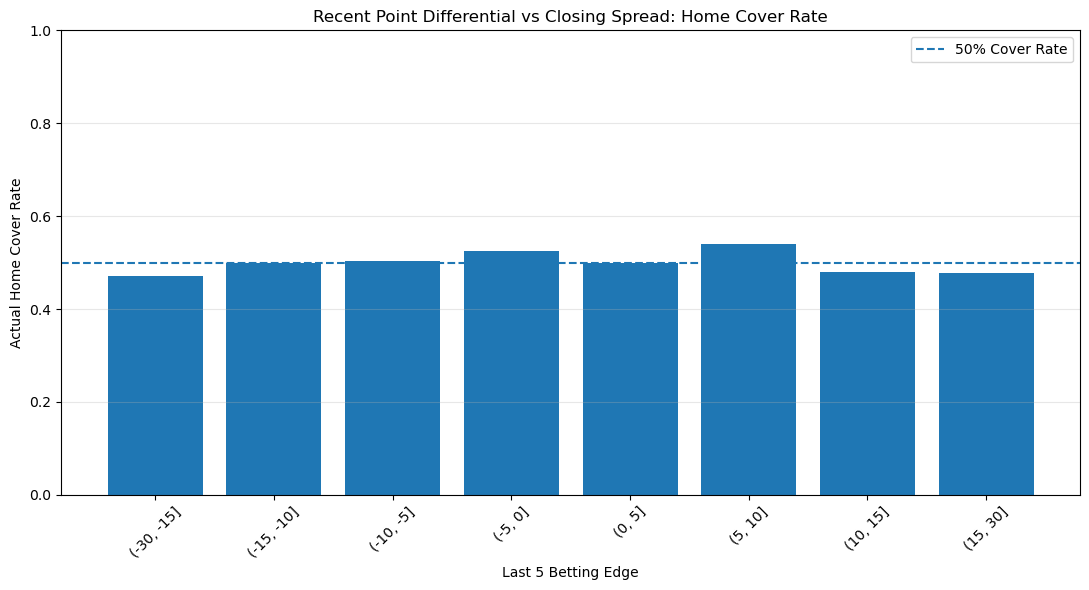

In [36]:
# Convert interval labels to strings for plotting
edge_analysis_last5["EDGE_LABEL"] = (
    edge_analysis_last5["BETTING_EDGE_GROUP_LAST5"].astype(str)
)

plt.figure(figsize=(11, 6))

plt.bar(
    edge_analysis_last5["EDGE_LABEL"],
    edge_analysis_last5["HOME_COVER_RATE"]
)

# 50% reference line
plt.axhline(
    y=0.5,
    linestyle="--",
    label="50% Cover Rate"
)

plt.xlabel("Last 5 Betting Edge")
plt.ylabel("Actual Home Cover Rate")
plt.title("Recent Point Differential vs Closing Spread: Home Cover Rate")

plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()